In [365]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [366]:
df= pd.read_csv("Student_Performance2")
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [367]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,7144.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.572788,55.224800
std,2.589309,17.343152,1.695863,2.868633,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [368]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        8428 non-null   object 
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  7144 non-null   float64
 5   Performance Index                 10000 non-null  int64  
dtypes: float64(1), int64(4), object(1)
memory usage: 468.9+ KB


In [369]:
df.isna().sum()

,0
Hours Studied,0
Previous Scores,0
Extracurricular Activities,1572
Sleep Hours,0
Sample Question Papers Practiced,2856
Performance Index,0


In [370]:
df.dtypes

,0
Hours Studied,int64
Previous Scores,int64
Extracurricular Activities,object
Sleep Hours,int64
Sample Question Papers Practiced,float64
Performance Index,int64


In [371]:
df["Extracurricular Activities"].unique()

array(['Yes', 'No', nan], dtype=object)

In [372]:
from sklearn.impute import SimpleImputer

impute_object = SimpleImputer(missing_values = np.nan , strategy = "most_frequent")
impute_object.fit(df[["Extracurricular Activities"]])
df[["Extracurricular Activities"]] = impute_object.transform(df[["Extracurricular Activities"]])

In [373]:
df["Extracurricular Activities"].unique()

array(['Yes', 'No'], dtype=object)

In [374]:
df.isna().sum()

,0
Hours Studied,0
Previous Scores,0
Extracurricular Activities,0
Sleep Hours,0
Sample Question Papers Practiced,2856
Performance Index,0


In [375]:
df["Sample Question Papers Practiced"].skew()

np.float64(-0.04025761626052509)

<Axes: ylabel='Frequency'>

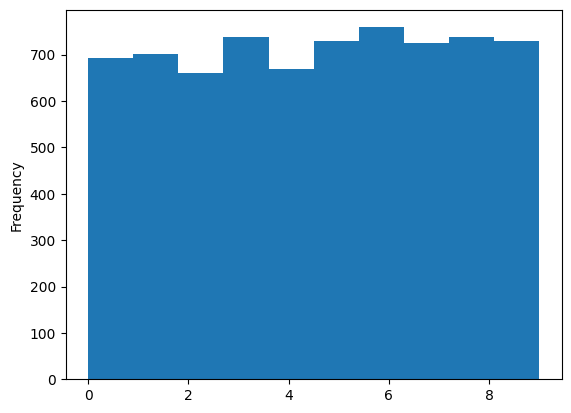

In [376]:
df["Sample Question Papers Practiced"].plot(kind= "hist")

In [377]:
imput_median = SimpleImputer(missing_values = np.nan , strategy = "median")
imput_median.fit(df[["Sample Question Papers Practiced"]])
df[["Sample Question Papers Practiced"]] = imput_median.transform(df[["Sample Question Papers Practiced"]])

In [378]:
df.isna().sum()

,0
Hours Studied,0
Previous Scores,0
Extracurricular Activities,0
Sleep Hours,0
Sample Question Papers Practiced,0
Performance Index,0


In [379]:
from sklearn.preprocessing import OneHotEncoder
#
le = OneHotEncoder(sparse_output=False, drop='first')
df["Extracurricular Activities"] = le.fit_transform(df[["Extracurricular Activities"]])

In [380]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1.0,9,1.0,91
1,4,82,0.0,4,2.0,65
2,8,51,1.0,7,2.0,45
3,5,52,1.0,5,2.0,36
4,7,75,0.0,8,5.0,66


In [381]:
from sklearn.preprocessing import StandardScaler
scalar =StandardScaler()
scalar.fit(df[["Previous Scores" , "Performance Index", "Sleep Hours"]])
df[["Previous Scores" , "Performance Index" , "Sleep Hours"]] = scalar.transform(df[["Previous Scores", "Performance Index" , "Sleep Hours"]])


In [382]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,1.704176,1.0,1.456205,1.0,1.862167
1,4,0.723913,0.0,-1.492294,2.0,0.508818
2,8,-1.063626,1.0,0.276805,2.0,-0.532220
3,5,-1.005963,1.0,-0.902594,2.0,-1.000687
4,7,0.320275,0.0,0.866505,5.0,0.560870


In [383]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [384]:
X = df.drop("Performance Index" , axis = 1)
y = df["Performance Index"]

In [385]:
x = X.T
y.shape

(10000,)

In [386]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [387]:
LR = LinearRegression()
LR.fit(X_train, y_train)
y_pred = LR.predict(X_test)

In [388]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

MSE = mean_squared_error(y_test , y_pred)
RMSE = np.sqrt(MSE)
MAE = mean_absolute_error(y_test , y_pred)
R2 = r2_score(y_test , y_pred)

In [389]:
print(f"MSE : {MSE}")
print(f"RMSE : {RMSE}")
print(f"MAE : {MAE}")
print(f"R2 : {R2}")

MSE : 0.011408451778441332
RMSE : 0.10681035426606042
MAE : 0.08524303956446275
R2 : 0.9886215832843565


In [390]:
LR.coef_

array([0.14893631, 0.91694386, 0.02486223, 0.04217925, 0.00972799])

In [391]:
LR.intercept_

np.float64(-0.797873466608633)

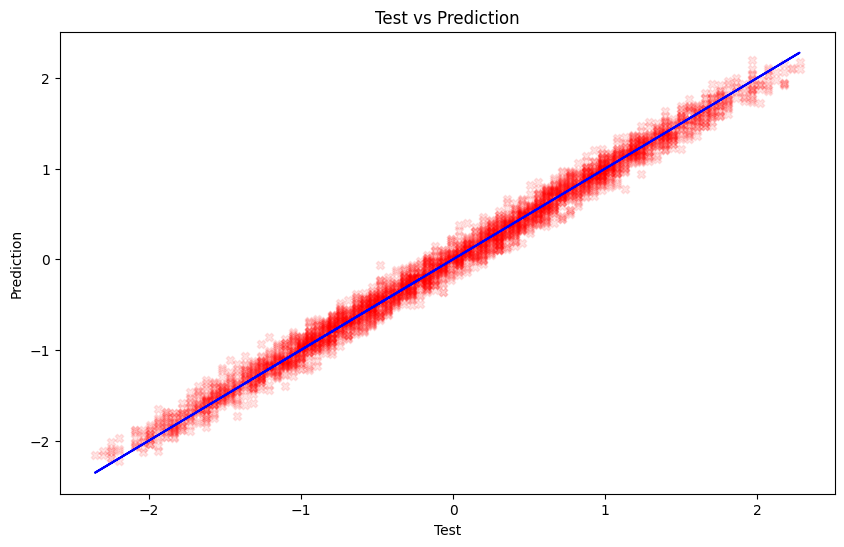

In [392]:

plt.figure(figsize=(10,6))
plt.scatter(y_test , y_pred ,color = "red" , alpha= .1 , marker = "X")
plt.plot(y_test , y_test , color = "blue")
plt.xlabel("Test")
plt.ylabel("Prediction")
plt.title("Test vs Prediction")
plt.show()


In [410]:
y_pred[:20]

array([-0.02075302, -1.69991008, -0.3810602 , -1.24534963, -0.62943362,
        0.2069    , -0.48490786,  1.62927547, -0.90547146,  0.87504392,
        0.44109008, -1.58020215,  0.29742396, -0.60891581, -0.32272538,
       -0.54764276,  0.1474948 ,  1.23631054,  0.55965825, -0.44692181])

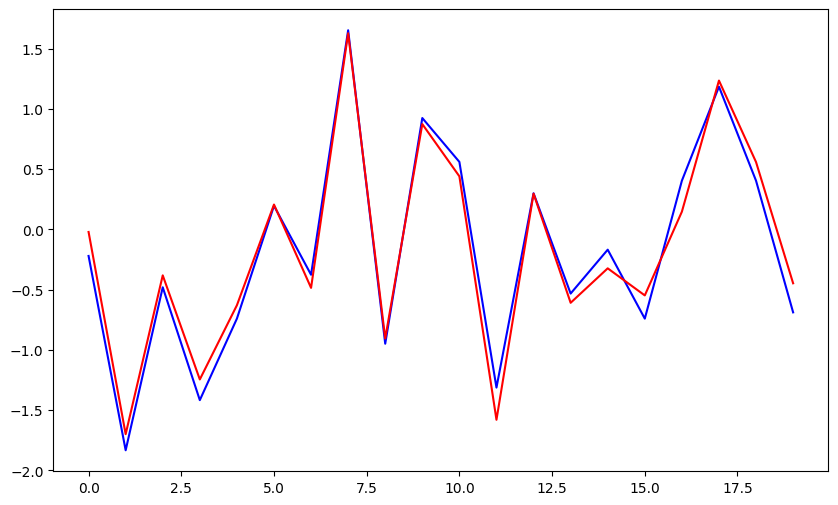

In [417]:
plt.figure(figsize=(10,6))

plt.plot( y_test.values[:20] , color = "blue")
plt.plot(y_pred[:20] , color = "red")
plt.show()

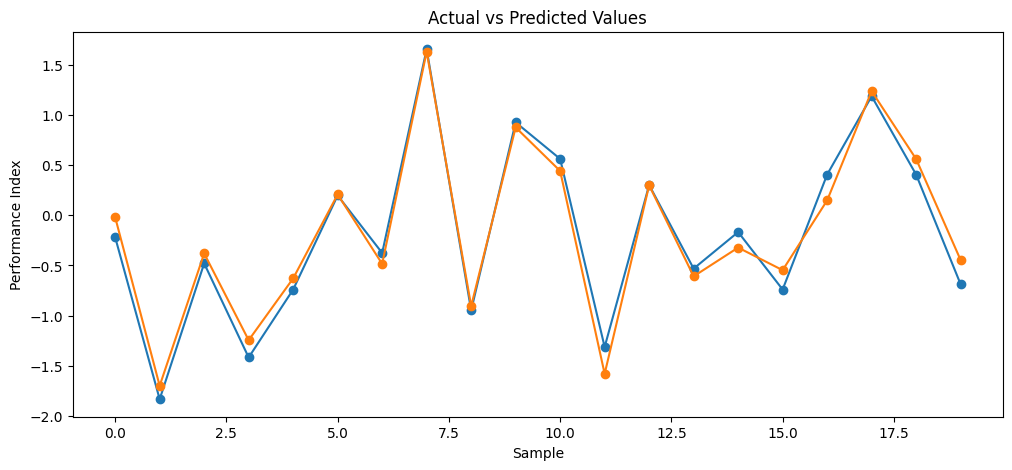

In [415]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(y_test.values[:20], marker='o', label='Actual')
plt.plot(y_pred[:20], marker='o', label='Predicted')

plt.xlabel('Sample')
plt.ylabel('Performance Index')
plt.title('Actual vs Predicted Values')

plt.show()